# Generation: from retrieved pages to a cited answer

The **G** in RAG. Notebook 03 found pages; here the model reads them and answers.

1. What the generator does, and how it fails
2. How we score answers
3. Techniques that shape the answer
4. Hands-on: baseline → better search → one change at a time
5. Judge every answer, then compare side by side

## 1. What the generator does

**Input:** the question and the top pages from search, as images, each labelled with its page id.
**Output:** JSON with `answer` (1–2 sentences), `citations` (the page ids it used) and `abstain` (true if the pages
do not hold the answer).

An answer can go wrong in five places:

![Five failure points: page not found, page misread, fact made up, wrong page cited, should have abstained](figures/answer_failures.png)

Failure 1 is search's fault (notebook 03); failures 2–5 happen in this notebook.

**Learn more:** [Claude docs: Reduce hallucinations](https://docs.claude.com/en/docs/test-and-evaluate/strengthen-guardrails/reduce-hallucinations)

## 2. How we score answers

| score | question it answers | how |
|---|---|---|
| **Correctness** | Does the answer say the same as the reference? | an 8B judge model; exact match fails on sentence-long answers |
| **Faithfulness** | Is every claim in the answer on the pages it was shown? | the 8B judge looks at the page images |
| **Citation precision** | Of the pages it cited, how many are right pages? | compare with the labels |
| **Citation recall** | Of the right pages it was shown, how many did it cite? | compare with the labels |
| **Abstain rate** | How often does it say "not in these pages"? | every question here has an answer, so lower is better |
| **Search miss / reading miss** | Was a wrong answer search's fault or the model's? | was any right page among those shown? |

Two cautions:
- **A judge is a model too.** Check it against your own labels before trusting small differences.
- **108 questions is a small sample.** Every accuracy comes with a 95% confidence interval; a difference is only
  real if the interval of the difference excludes zero.

**Learn more:** [Hamel Husain: Your AI product needs evals](https://hamel.dev/blog/posts/evals/) · deeper:
[Eugene Yan: LLM-evaluators](https://eugeneyan.com/writing/llm-evaluators/),
[RAGAS: Faithfulness](https://docs.ragas.io/en/stable/concepts/metrics/available_metrics/faithfulness/),
[Adding error bars to evals](https://arxiv.org/abs/2411.00640)

## 3. Techniques that shape the answer

| technique | what it does | used in practice | here |
|---|---|---|---|
| **Prompt rules** | tell the model to cite pages and to abstain when unsure | every RAG system | 7d |
| **Structured output** | force valid JSON with a schema (constrained decoding) | vLLM, OpenAI, Anthropic APIs | always on |
| **Context size** | how many pages to show | the top-k knob in every RAG system | 7a |
| **Context format** | page images, extracted text, or both | text is standard; images for charts and scans | 7b |
| **Context order** | where the best page sits; models read the middle worst | "lost in the middle" | 7c |
| **Decoding settings** | temperature, length limit, repetition penalty | everywhere | 7e |
| **Think first** | write short reasoning before the answer (chain of thought) | reasoning models, agents | 7f |
| **Self-consistency** | answer several times, keep the majority | high-stakes answers | not run |
| **Context compression** | keep only the relevant sentences before answering | long-context systems (LLMLingua) | not run |
| **Iterative retrieval** | check the answer, search again if needed (Self-RAG, CRAG) | agentic RAG | Day 4 |
| **Fine-tuning for RAG** | train on right pages + distractors to cite or abstain (RAFT) | domain RAG | Day 5 |

**Learn more:** [vLLM: Structured outputs](https://docs.vllm.ai/en/latest/features/structured_outputs.html) · deeper:
[Lost in the Middle](https://arxiv.org/abs/2307.03172), [Chain of thought](https://arxiv.org/abs/2201.11903),
[Self-consistency](https://arxiv.org/abs/2203.11171), [LongLLMLingua](https://arxiv.org/abs/2310.06839),
[RAFT](https://arxiv.org/abs/2403.10131)

## 4. Setup

In [1]:
# What this cell does:
# 1. load the dev questions, the pages (image + text) and the rankings saved by notebook 03
# 2. keep each question's right pages and whether its evidence is visual (chart, table, image)
import base64
import hashlib
import io
import json
import random
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache
from pathlib import Path

from datasets import load_dataset
from openai import OpenAI

from vdoc_agent.serve import VLLMServer

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "evals").is_dir())
CACHE = ROOT / "data" / "cache" / "answers"      # answers and verdicts are saved here
CACHE.mkdir(parents=True, exist_ok=True)

MODEL = "Qwen/Qwen3-VL-4B-Instruct"               # answers
JUDGE = "Qwen/Qwen3-VL-8B-Instruct-FP8"           # grades

dev = [json.loads(line) for line in (ROOT / "evals" / "dev.jsonl").read_text().splitlines()]
corpus = load_dataset("vidore/vidore_v3_pharmaceuticals", "corpus")["test"]
row_of = {cid: i for i, cid in enumerate(corpus["corpus_id"])}
text_of = dict(zip(corpus["corpus_id"], corpus["markdown"], strict=True))
runs = json.loads((ROOT / "data" / "cache" / "search" / "runs.json").read_text())   # from notebook 03

grades = [{p["corpus_id"]: p["score"] for p in q["pages"]} for q in dev]
visual = [bool(set(q["content_type"]) - {"Text"}) for q in dev]
print(len(dev), "questions | search runs available:", list(runs))

/storage/homefs/kr23w045/vdoc-agent/envs/train/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


108 questions | search runs available: ['BM25', 'Dense (Qwen3-Embedding)', 'ColQwen2 (page images)', 'Hybrid text (BM25 + Dense)', 'Hybrid all three', 'Hybrid all three + rerank', 'Dense, chunked pages', 'BM25 + document title', 'Dense + document title', 'Dense, first 256 numbers', 'Dense, first 128 numbers', 'Dense, binary (1 bit each)', 'FAISS Flat (exact)', 'FAISS HNSW', 'FAISS IVF']


In [2]:
# What this cell does:
# 1. the two prompts: with rules (cite, abstain) and plain
# 2. answer(): builds the message (pages as images and/or text, then the question), asks the model for JSON
# 3. run(): answers every question with one setup, saves the answers, prints quick checks
SYSTEM_RULES = (
    "You answer questions about documents using only the pages you are given. "
    "Answer in one or two sentences. In citations, list the ids of the pages that contain the answer. "
    "If the pages do not contain the answer, set abstain to true and leave answer empty."
)
SYSTEM_PLAIN = "Answer the question using the pages."
THINK = " First write your reasoning in at most three sentences in the reasoning field."

@lru_cache(maxsize=4096)
def page_image(cid, max_side=1280):
    img = corpus[row_of[cid]]["image"].convert("RGB")
    img.thumbnail((max_side, max_side))
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=90)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()

def answer(q, pages, cfg):
    content = []
    for cid in pages:
        content.append({"type": "text", "text": f"Page {cid}:"})
        if cfg["view"] in ("image", "both"):
            content.append({"type": "image_url", "image_url": {"url": page_image(cid)}})
        if cfg["view"] in ("text", "both"):
            content.append({"type": "text", "text": text_of[cid][:6000]})
    content.append({"type": "text", "text": f"Question: {q['query']}"})

    system = SYSTEM_RULES if cfg["prompt"] == "rules" else SYSTEM_PLAIN
    fields = {"reasoning": {"type": "string"}} if cfg["think"] else {}
    fields |= {"answer": {"type": "string"},
               "citations": {"type": "array", "items": {"type": "integer", "enum": list(pages)}},
               "abstain": {"type": "boolean"}}
    resp = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "system", "content": system + (THINK if cfg["think"] else "")},
                  {"role": "user", "content": content}],
        response_format={"type": "json_schema", "json_schema": {"name": "answer", "schema": {
            "type": "object", "properties": fields, "required": list(fields)}}},
        temperature=0,
        max_tokens=700 if cfg["think"] else 300,
        extra_body={"repetition_penalty": cfg["repetition_penalty"]},
    )
    choice = resp.choices[0]
    try:
        out = json.loads(choice.message.content)
    except json.JSONDecodeError:                  # cut off or broken JSON: counts as a failed answer
        out = {"answer": "", "citations": [], "abstain": False}
    out["finish_reason"] = choice.finish_reason
    return out

def setup_key(cfg):
    """A short id for a setup and the search rankings it uses: changing either gives new answers."""
    payload = json.dumps([cfg, runs[cfg["search"]]], sort_keys=True)
    return hashlib.md5(payload.encode()).hexdigest()[:10]

DEFAULT = dict(search="Hybrid all three + rerank", k=3, view="image", order="best first",
               prompt="rules", repetition_penalty=1.0, think=False)
setups, answers = {}, {}

def run(name, **changes):
    cfg = {**DEFAULT, **changes}
    setups[name] = cfg
    key = setup_key(cfg)
    path = CACHE / f"{key}.jsonl"
    if path.exists():
        rows = [json.loads(line) for line in path.read_text().splitlines()]
    else:
        def one(i):
            pages = runs[cfg["search"]][i][: cfg["k"]]
            pages = pages[::-1] if cfg["order"] == "best last" else pages
            return {"query_id": dev[i]["query_id"], "shown": pages, "pred": answer(dev[i], pages, cfg)}
        with ThreadPoolExecutor(8) as pool:
            rows = list(pool.map(one, range(len(dev))))
        path.write_text("".join(json.dumps(r) + "\n" for r in rows))
    answers[name] = rows

    shown_ok = sum(bool(set(r["shown"]) & set(g)) for r, g in zip(rows, grades, strict=True)) / len(rows)
    abstain = sum(r["pred"]["abstain"] for r in rows) / len(rows)
    cited = [(set(r["pred"]["citations"]), set(g)) for r, g in zip(rows, grades, strict=True)]
    cite_p = sum(len(c & g) / len(c) if c else 0 for c, g in cited) / len(rows)
    cut = sum(r["pred"]["finish_reason"] == "length" for r in rows)
    print(f"{name:30} right page shown {shown_ok:4.0%} | abstain {abstain:4.0%} | "
          f"citation precision {cite_p:.2f} | cut off {cut}")

def example(name, i=0):
    r = answers[name][i]
    print("Q:     ", dev[i]["query"])
    print("REF:   ", dev[i]["answer"])
    print("ANSWER:", r["pred"])
    print("shown:", r["shown"], "| right pages:", sorted(grades[i]))

Start the answer model (one model fits on the GPU at a time; the judge comes in section 8).

In [3]:
server = VLLMServer(MODEL, max_model_len=16384).start()
client = OpenAI(base_url=server.base_url, api_key="none")
print("serving", MODEL)

serving Qwen/Qwen3-VL-4B-Instruct


## 5. Baseline: BM25, top 3 pages

The same setup as the first rough version, so later numbers have a reference point.

In [4]:
run("baseline (BM25, top 3)", search="BM25")
example("baseline (BM25, top 3)")

baseline (BM25, top 3)         right page shown  79% | abstain  11% | citation precision 0.58 | cut off 2
Q:      Does the Bolar exception help reduce the time it takes for generic drugs to reach the market after a patent expires?
REF:    Yes, the Bolar exception helps reduce the time it takes for generic drugs to reach the market after a patent expires by allowing generic manufacturers to conduct the necessary studies and trials for regulatory approval while the original drug's patent is still active.
ANSWER: {'answer': "Yes, the Bolar exception helps reduce the time it takes for generic drugs to reach the market after a patent expires by allowing third parties to use the patented invention for regulatory approval purposes without the patent holder's consent, which is necessary to obtain marketing approval.", 'citations': [331, 333, 521], 'abstain': False, 'finish_reason': 'stop'}
shown: [333, 331, 521] | right pages: [331, 332, 333, 335, 336, 337, 338, 339, 341, 342, 343, 344, 351, 5

## 6. Better search, same model

The best search from notebook 03 (hybrid of all three + reranker). The model and prompt stay the same, so any change
comes from which pages it sees.

In [5]:
run("best search, top 3")
example("best search, top 3")

best search, top 3             right page shown  82% | abstain   3% | citation precision 0.62 | cut off 4
Q:      Does the Bolar exception help reduce the time it takes for generic drugs to reach the market after a patent expires?
REF:    Yes, the Bolar exception helps reduce the time it takes for generic drugs to reach the market after a patent expires by allowing generic manufacturers to conduct the necessary studies and trials for regulatory approval while the original drug's patent is still active.
ANSWER: {'answer': "Yes, the Bolar exception helps reduce the time it takes for generic drugs to reach the market after a patent expires by allowing third parties to use a patented invention for regulatory approval purposes without the patent holder's consent, which facilitates market entry for generics.", 'citations': [333], 'abstain': False, 'finish_reason': 'stop'}
shown: [344, 333, 331] | right pages: [331, 332, 333, 335, 336, 337, 338, 339, 341, 342, 343, 344, 351, 521, 549, 560]


## 7. Experiments: one change at a time

Every setup below is *best search, top 3* with exactly one thing changed.

### 7a. How many pages?
One page is cheap but often misses; five gives more evidence but more to read.

In [6]:
run("top 1", k=1)
run("top 5", k=5)

top 1                          right page shown  56% | abstain  17% | citation precision 0.56 | cut off 1
top 5                          right page shown  87% | abstain   3% | citation precision 0.57 | cut off 6


### 7b. What the model sees: images, text, or both?
Text is what most RAG systems use; images keep charts and tables intact.

In [7]:
run("pages as text", view="text")
run("pages as image + text", view="both")

pages as text                  right page shown  82% | abstain   2% | citation precision 0.54 | cut off 6
pages as image + text          right page shown  82% | abstain   4% | citation precision 0.61 | cut off 1


### 7c. Page order
With 5 pages, put the best page last instead of first. Models tend to use the start and end of their input best.

In [8]:
run("top 5, best page last", k=5, order="best last")

top 5, best page last          right page shown  87% | abstain   1% | citation precision 0.68 | cut off 3


### 7d. Prompt rules
The same request without the instructions to cite and to abstain.

In [9]:
run("no cite/abstain rules", prompt="plain")

no cite/abstain rules          right page shown  82% | abstain   1% | citation precision 0.58 | cut off 7


### 7e. Repetition guard
Small models sometimes repeat a phrase until they hit the length limit. A repetition penalty makes repeated tokens
less likely.

In [10]:
run("repetition penalty 1.1", repetition_penalty=1.1)

repetition penalty 1.1         right page shown  82% | abstain   6% | citation precision 0.59 | cut off 0


### 7f. Think first
The model writes up to three sentences of reasoning before the answer (chain of thought).

In [11]:
run("think first", think=True)
example("think first")
server.stop()

think first                    right page shown  82% | abstain  15% | citation precision 0.47 | cut off 15
Q:      Does the Bolar exception help reduce the time it takes for generic drugs to reach the market after a patent expires?
REF:    Yes, the Bolar exception helps reduce the time it takes for generic drugs to reach the market after a patent expires by allowing generic manufacturers to conduct the necessary studies and trials for regulatory approval while the original drug's patent is still active.
ANSWER: {'reasoning': 'The text on page 333 explains that without the Bolar exception, competitors must wait until the patent expires to begin regulatory approval processes, which can take time. The Bolar exception allows for activities like studies and trials to be conducted during the patent term, thereby facilitating quicker market entry for generics after the patent expires. This is further supported by the abstract on page 331, which states the Bolar exception supports market entry

## 8. Judge every answer

Two questions per answer, both asked to the 8B judge:
- **Correct?** Compare with the reference answer (text only).
- **Faithful?** Look at the pages the model was shown: is every claim in the answer there?

Abstentions and empty answers count as incorrect and are left out of faithfulness.

In [12]:
# What this cell does:
# 1. start the 8B judge
# 2. for every setup: ask "correct?" (vs the reference) and "faithful?" (vs the page images); save the verdicts
# 3. stop the judge
judge_server = VLLMServer(JUDGE, max_model_len=16384).start()
judge_client = OpenAI(base_url=judge_server.base_url, api_key="none")

CORRECT = ("You grade an answer against a reference answer. The answer is correct if it states the same key facts "
           "as the reference: numbers, names and dates must match. Extra detail is fine. Missing or wrong key facts "
           "make it incorrect.")
FAITHFUL = ("You check whether an answer is supported by the pages shown. It is supported if every factual claim "
            "in it can be found in these pages. Do not judge whether it is complete.")

def verdict(system, content, key):
    resp = judge_client.chat.completions.create(
        model=JUDGE,
        messages=[{"role": "system", "content": system}, {"role": "user", "content": content}],
        response_format={"type": "json_schema", "json_schema": {"name": "v", "schema": {
            "type": "object", "properties": {key: {"type": "boolean"}}, "required": [key]}}},
        temperature=0, max_tokens=20)
    return json.loads(resp.choices[0].message.content)[key]

def grade(i, r):
    pred = r["pred"]
    if pred["abstain"] or not pred["answer"].strip():
        return {"correct": False, "faithful": None}
    q = dev[i]
    correct = verdict(CORRECT, f"Question: {q['query']}\nReference answer: {q['answer']}\n"
                               f"Answer to grade: {pred['answer']}", "correct")
    pages = [{"type": "image_url", "image_url": {"url": page_image(c)}} for c in r["shown"]]
    faithful = verdict(FAITHFUL, pages + [{"type": "text", "text": f"Answer to check: {pred['answer']}"}],
                       "supported")
    return {"correct": correct, "faithful": faithful}

verdicts = {}
for name, cfg in setups.items():
    path = CACHE / f"{setup_key(cfg)}.judged.json"
    if not path.exists():
        with ThreadPoolExecutor(8) as pool:
            path.write_text(json.dumps(list(pool.map(grade, range(len(dev)), answers[name]))))
    verdicts[name] = json.loads(path.read_text())
    print("judged", name)
judge_server.stop()

judged baseline (BM25, top 3)
judged best search, top 3
judged top 1
judged top 5
judged pages as text
judged pages as image + text
judged top 5, best page last
judged no cite/abstain rules
judged repetition penalty 1.1
judged think first


## 9. Side by side

Accuracy with its 95% confidence interval, the difference from *best search, top 3* with its own interval, and the
other scores. A difference is real when its interval does not include 0.

In [13]:
# What this cell does:
# 1. bootstrap: resample the 108 questions 2,000 times to get a 95% interval for accuracy and for differences
# 2. one row per setup: accuracy, difference vs best search, faithfulness, citations, abstain, text vs visual,
#    and how many wrong answers were search misses vs reading misses
def mean(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else float("nan")

def interval(values, n=2000, seed=0):
    rng = random.Random(seed)
    means = sorted(mean(rng.choice(values) for _ in values) for _ in range(n))
    return means[int(0.025 * n)], means[int(0.975 * n)]

REF = "best search, top 3"
ref_correct = [v["correct"] for v in verdicts[REF]]
table = {}
print(f"{'setup':30}{'accuracy [95% CI]':>20}{'vs best [95% CI]':>21}{'faithful':>9}{'cite P':>8}{'cite R':>8}"
      f"{'abstain':>8}{'text':>6}{'visual':>7}{'search miss':>12}{'reading miss':>13}")
for name, rows in answers.items():
    v = verdicts[name]
    correct = [x["correct"] for x in v]
    shown_ok = [bool(set(r["shown"]) & set(g)) for r, g in zip(rows, grades, strict=True)]
    cite_p = [len(set(r["pred"]["citations"]) & set(g)) / len(r["pred"]["citations"]) if r["pred"]["citations"] else 0
              for r, g in zip(rows, grades, strict=True)]
    cite_r = [len(set(r["pred"]["citations"]) & set(g) & set(r["shown"])) / len(set(g) & set(r["shown"]))
              for r, g in zip(rows, grades, strict=True) if set(g) & set(r["shown"])]
    lo, hi = interval(correct)
    diff = [a - b for a, b in zip(correct, ref_correct, strict=True)]
    dlo, dhi = interval(diff)
    table[name] = {"accuracy": mean(correct), "lo": lo, "hi": hi, "diff": mean(diff), "diff_lo": dlo, "diff_hi": dhi,
                   "faithful": mean(x["faithful"] for x in v if x["faithful"] is not None),
                   "citation_precision": mean(cite_p), "citation_recall": mean(cite_r),
                   "abstain": mean(r["pred"]["abstain"] for r in rows)}
    print(f"{name:30}{mean(correct):8.0%} [{lo:4.0%}, {hi:4.0%}]"
          f"{mean(diff):+7.0%} [{dlo:+4.0%}, {dhi:+4.0%}]"
          f"{table[name]['faithful']:9.0%}{mean(cite_p):8.2f}{mean(cite_r):8.2f}{table[name]['abstain']:8.0%}"
          f"{mean(c for c, vi in zip(correct, visual, strict=True) if not vi):6.0%}"
          f"{mean(c for c, vi in zip(correct, visual, strict=True) if vi):7.0%}"
          f"{sum(not c and not s for c, s in zip(correct, shown_ok, strict=True)):12d}"
          f"{sum(not c and s for c, s in zip(correct, shown_ok, strict=True)):13d}")

setup                            accuracy [95% CI]     vs best [95% CI] faithful  cite P  cite R abstain  text visual search miss reading miss
baseline (BM25, top 3)             38% [ 29%,  47%]    -8% [-19%,  +1%]      68%    0.58    0.83     11%   43%    34%          21           46
best search, top 3                 46% [ 37%,  56%]    +0% [ +0%,  +0%]      71%    0.62    0.75      3%   64%    33%          17           41
top 1                              35% [ 27%,  44%]   -11% [-20%,  -2%]      72%    0.56    1.00     17%   47%    26%          40           30
top 5                              48% [ 39%,  57%]    +2% [ -6%,  +9%]      74%    0.57    0.61      3%   57%    41%          11           45
pages as text                      55% [ 45%,  64%]    +8% [ -1%, +18%]      62%    0.54    0.84      2%   70%    43%          15           34
pages as image + text              52% [ 43%,  61%]    +6% [ +0%, +12%]      75%    0.61    0.77      4%   72%    36%          16           36

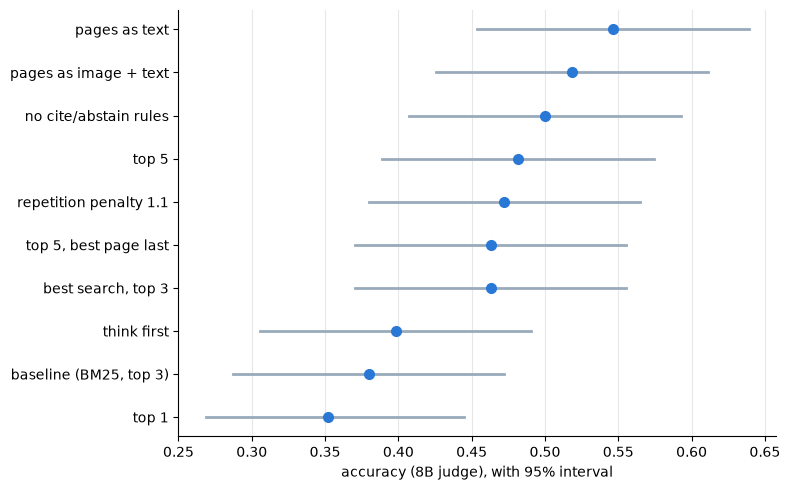

In [14]:
# What this cell does: accuracy of every setup with its 95% interval, best on top
import matplotlib.pyplot as plt

order = sorted(table, key=lambda n: table[n]["accuracy"])
fig, ax = plt.subplots(figsize=(8, 0.4 * len(order) + 1))
for y, name in enumerate(order):
    t = table[name]
    ax.plot([t["lo"], t["hi"]], [y, y], color="#9ab", lw=2)
    ax.plot(t["accuracy"], y, "o", color="#2a78d6", ms=7)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("accuracy (8B judge), with 95% interval")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [15]:
# What this cell does: log every setup's scores to reports/runs/
from vdoc_agent.runlog import log_run

for name, t in table.items():
    log_run(f"answer-{name}", {**setups[name], "model": MODEL, "judge": JUDGE, "split": "dev"}, t)
print("logged", len(table), "setups")

logged 10 setups


## What to look for

- Did better search lift accuracy, and is the difference's interval clear of 0?
- How many wrong answers are **search misses** vs **reading misses** now? Which one should you work on next?
- Pages: does top 5 beat top 3, and does putting the best page last hurt?
- Images vs text: who wins on the **visual** questions?
- Without the rules, does the model stop abstaining or cite worse?
- Did the repetition penalty remove the cut-off answers? Did thinking first help?
- Faithfulness vs correctness: an answer can be faithful to the pages and still wrong, if the pages were the wrong ones.